### Step 1: Mount the Google Drive

Remember to use GPU runtime before mounting your Google Drive. (Runtime --> Change runtime type).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Step 2: Open the project directory

Replace `Your_Dir` with your own path.

In [2]:
%cd /content
import os
if not os.path.exists('/content/emg2qwerty'):
    !GIT_LFS_SKIP_SMUDGE=1 git clone https://github.com/valerieychu/emg2qwerty.git
%cd /content/emg2qwerty
!git pull

/content
Cloning into 'emg2qwerty'...
remote: Enumerating objects: 157, done.
remote: Counting objects: 100% (157/157), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 157 (delta 40), reused 156 (delta 39), pack-reused 0 (from 0)
Receiving objects: 100% (157/157), 33.51 MiB | 17.63 MiB/s, done.
Resolving deltas: 100% (40/40), done.
/content/emg2qwerty
Already up to date.


### Step 3: Install required packages

After installing them, Colab will require you to restart the session.

In [4]:
!python --version

Python 3.13.16


In [3]:
%cd /content/emg2qwerty
!pip -q install uv
!uv venv --python 3.10 /content/venv
!CMAKE_POLICY_VERSION_MINIMUM=3.5 uv pip install --python /content/venv/bin/python -r requirements.txt

/content/emg2qwerty
Using CPython 3.10.22
Creating virtual environment at: /content/venv
Activate with: source /content/venv/bin/activate
Using Python 3.10.22 environment at: /content/venv
Resolved 141 packages in 4.35s
Prepared 140 packages in 2m 07s
Installed 141 packages in 773ms
 + absl-py==2.5.1
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.6
 + annotated-types==0.8.0
 + antlr4-python3-runtime==4.9.3
 + anyio==4.16.0
 + async-timeout==5.0.1
 + attrs==26.1.0
 + certifi==2026.11.20
 + cfgv==3.5.0
 + charset-normalizer==3.5.2
 + click==8.1.7
 + cloudpickle==3.1.3
 + contourpy==1.3.2
 + coverage==7.16.2
 + cycler==0.12.1
 + datasets==2.19.2
 + decorator==5.3.2
 + dill==0.3.8
 + distlib==0.4.4
 + exceptiongroup==1.3.2
 + execnet==2.1.2
 + filelock==4.1.0
 + fonttools==4.65.0
 + frozenlist==1.8.0
 + fsspec==2024.3.1
 + grpcio==1.85.3
 + h11==0.16.0
 + h5py==3.11.0
 + hf-xet==1.8.0
 + httpcore==1.0.9
 + httpx==0.28.1
 + huggingface-hub==1.16.1
 +

### Step 4: Start your experiments!

- Remember to download and copy the dataset to this directory: `Your_Dir/emg2qwerty/data`.
- You may now start your experiments with any scripts! Below are examples of single-user training and testing (greedy decoding).
- **There are two ways to track the logs:**
  - 1. Keep `--multirun`, and the logs will not be printed here, but they will be saved in the folder `logs`, e.g., `logs/2025-02-09/18-24-15/submitit_logs/`.
  - 2. Comment out `--multirun` and the logs will be printed in this notebook, but they will not be saved.

In [6]:
DRIVE = '/content/drive/MyDrive/Colab Notebooks/ECE_247A'
%cd /content/emg2qwerty
!mkdir -p '{DRIVE}/logs' data
!ln -sfn '{DRIVE}/logs' /content/emg2qwerty/logs
!cp -n '{DRIVE}'/data/*.hdf5 data/

/content/emg2qwerty
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


#### Training

- The checkpoints are saved in the folder `logs`, e.g., `logs/2025-02-09/18-24-15/checkpoints/`.

In [4]:
DRIVE = '/content/drive/MyDrive/Colab Notebooks/ECE_247A'
%cd /content/emg2qwerty
!mkdir -p data "{DRIVE}/logs"
!ln -sfn "{DRIVE}/logs" /content/emg2qwerty/logs
!rsync -ah --progress "{DRIVE}/data/" /content/emg2qwerty/data/
!ls data/*.hdf5 | wc -l
!du -sh data

/content/emg2qwerty
sending incremental file list
./
2021-06-02-1622679967-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        323.69M 100%   73.67MB/s    0:00:04 (xfr#1, to-chk=17/19)
2021-06-02-1622681518-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        296.54M 100%   38.43MB/s    0:00:07 (xfr#2, to-chk=16/19)
2021-06-02-1622682789-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        306.72M 100%   42.42MB/s    0:00:06 (xfr#3, to-chk=15/19)
2021-06-03-1622764398-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        255.18M 100%   15.27MB/s    0:00:15 (xfr#4, to-chk=14/19)
2021-06-03-1622765527-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        262.45M 100%   29.87MB/s    0:00:08 (xfr#5, to-chk=13/19)
2021-06-03-1622766673-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f.hdf5
        255.29M 100%   18.25MB/s    0:00:13 (xfr#6, to-chk=12/19)
2021-06-04-1622861066-keystro

In [15]:
%env MPLBACKEND=Agg

env: MPLBACKEND=Agg


In [16]:
!MPLBACKEND=Agg /content/venv/bin/python -m emg2qwerty.train \
  user="single_user" \
  trainer.accelerator=gpu trainer.devices=1 \
  trainer.max_epochs=40

[2026-11-22 10:35:55,461][__main__][INFO] - 
Config:
user: single_user
dataset:
  train:
  - user: 89335547
    session: 2021-06-03-1622765527-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-02-1622681518-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-04-1622863166-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-22-1627003020-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-21-1626916256-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-22-1627004019-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-05-1622885888-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-02-1622679967-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f

AI-generate code to visualize the CER, loss, and learning rate schedule of validation and test.

In [8]:
%%writefile /content/plot_curves.py
import glob, os, sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

run = sys.argv[1]
event_files = sorted(glob.glob(f"{run}/lightning_logs/*/events.out.tfevents.*"))
assert event_files, f"No TensorBoard event files under {run}/lightning_logs"
ea = EventAccumulator(os.path.dirname(event_files[-1]), size_guidance={"scalars": 0})
ea.Reload()
tags = ea.Tags()["scalars"]
print("Logged scalars:", tags)

STEPS_PER_EPOCH = 120  # from your log: epoch 0 ended at global step 120

def series(tag):
    ev = ea.Scalars(tag)
    return [e.step / STEPS_PER_EPOCH for e in ev], [e.value for e in ev]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1) CER
for tag in ["train/CER", "val/CER"]:
    if tag in tags:
        x, y = series(tag)
        axes[0].plot(x, y, label=tag)
axes[0].set_ylim(0, 110)  # epoch 0 is >1000, which would flatten everything else
axes[0].set(xlabel="epoch", ylabel="CER (%)", title="Character error rate")
axes[0].legend(); axes[0].grid(alpha=0.3)

# 2) Loss
for tag in ["train/loss", "val/loss"]:
    if tag in tags:
        x, y = series(tag)
        axes[1].plot(x, y, label=tag)
axes[1].set(xlabel="epoch", ylabel="CTC loss", title="Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

# 3) Learning rate
lr_tags = [t for t in tags if t.startswith("lr-")]
for tag in lr_tags:
    x, y = series(tag)
    axes[2].plot(x, y, label=tag)
axes[2].set(xlabel="epoch", ylabel="learning rate", title="LR schedule")
if lr_tags:
    axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
out = f"{run}/curves.png"
plt.savefig(out, dpi=150)
print("Saved", out)

Overwriting /content/plot_curves.py


Logged scalars: ['hp_metric', 'lr-Adam', 'train/loss', 'epoch', 'val/loss', 'val/CER', 'val/IER', 'val/DER', 'val/SER', 'train/CER', 'train/IER', 'train/DER', 'train/SER', 'test/loss', 'test/CER', 'test/IER', 'test/DER', 'test/SER']
Saved /content/emg2qwerty/logs/2026-11-22/10-35-55/curves.png


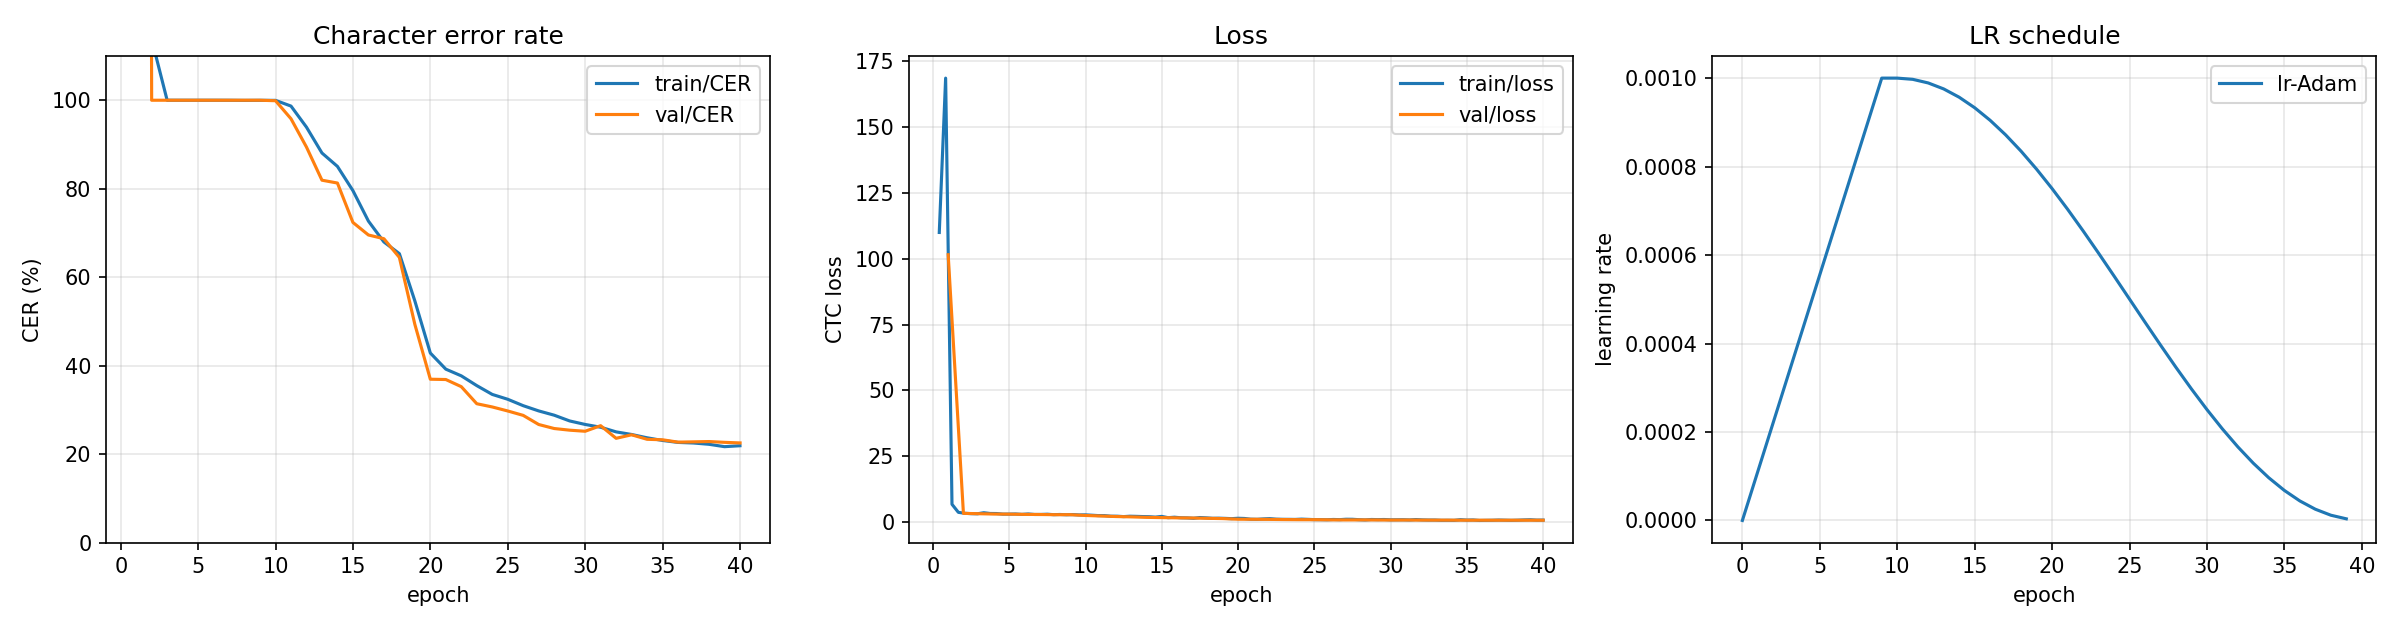

In [ ]:
from IPython.display import Image

RUN = "/content/emg2qwerty/logs/2026-11-22/10-35-55"
!MPLBACKEND=Agg /content/venv/bin/python /content/plot_curves.py "{RUN}"

Image(f"{RUN}/curves.png")

#### Testing:

- Replace `Your_Path_to_Checkpoint` with your checkpoint path.

In [5]:
!cp "/content/drive/MyDrive/Colab Notebooks/ECE_247A/logs/2026-11-22/10-35-55/checkpoints/epoch=39-step=4800.ckpt" /content/best_baseline.ckpt

!MPLBACKEND=Agg /content/venv/bin/python -m emg2qwerty.train \
  user="single_user" \
  checkpoint=/content/best_baseline.ckpt \
  train=False trainer.accelerator=gpu \
  decoder=ctc_greedy

[2026-11-22 20:01:18,916][__main__][INFO] - 
Config:
user: single_user
dataset:
  train:
  - user: 89335547
    session: 2021-06-03-1622765527-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-02-1622681518-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-04-1622863166-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-22-1627003020-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-21-1626916256-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-07-22-1627004019-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-05-1622885888-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f
  - user: 89335547
    session: 2021-06-02-1622679967-keystrokes-dca-study@1-0efbe614-9ae6-4131-9192-4398359b4f5f

We have:

```{'val_metrics': [{'val/loss': 0.7447391748428345,
                  'val/CER': 22.5299072265625,
                  'val/IER': 6.1364641189575195,
                  'val/DER': 1.9273371696472168,
                  'val/SER': 14.466105461120605}],
 'test_metrics': [{'test/loss': 0.7691948413848877,
                   'test/CER': 23.924789428710938,
                   'test/IER': 5.3814568519592285,
                   'test/DER': 2.1180031299591064,
                   'test/SER': 16.425329208374023}],
 'best_checkpoint': '/content/emg2qwerty/logs/2026-11-22/10-35-55/checkpoints/epoch=39-step=4800.ckpt'}```

CER = (S + D + I) / Nchar = (# substitutions + # deletions + # insertions) / total # characters

A lower CER is better. CER [represents](https://towardsdatascience.com/evaluating-ocr-output-quality-with-character-error-rate-cer-and-word-error-rate-wer-853175297510/) the edit distance between the predicted text and the reference text divided by the number of reference characters. The lower the CER value (with 0 being a perfect score), the better the performance of our baseline TDS-Conv-CTC model, which decodes sEMG signals into typed text with greedy decoding. It reached about 22.53% validation CER and 23.92% test CER, which is lower than the 30% validation CER the instructions reported, but still means that around every 4th or 5th reference characters the person typed was incorrect.